Example for N = 15, a = 2

In [4]:
import pennylane as qml
import numpy as np

from math import gcd

In [9]:
# Construct modular multiplication operator

N = 15
a = 2

assert gcd(N, a) == 1

n_target = (N - 1).bit_length()
dimension = 2 ** n_target

U = np.zeros((dimension, dimension), dtype=complex)
for x in range(dimension):
    y = (a * x) % N if x < N else x
    U[y, x] = 1

In [ ]:
# Prepare circuit

n_estimation = 4
estimation_wires = list(range(n_estimation))
target_wires = list(range(n_estimation, n_estimation + n_target))

shor = qml.device("default.qubit", wires=n_estimation + n_target)

@qml.qnode(shor)
def circuit():
    qml.PauliX(wires=target_wires[-1]) # prepare |1> input state or better said |0001> state

    for wire in estimation_wires:
        qml.Hadamard(wires=wire)
    
    for j, wire in enumerate(estimation_wires):
        power = 2 **(n_estimation - 1 - j)
        U_power = np.linalg.matrix_power(U, power)

        qml.ctrl(qml.QubitUnitary, control=wire) (
            U_power, wires=target_wires
        )

    qml.adjoint(qml.QFT)(
        wires=estimation_wires
    )

    return qml.probs(wires=estimation_wires)


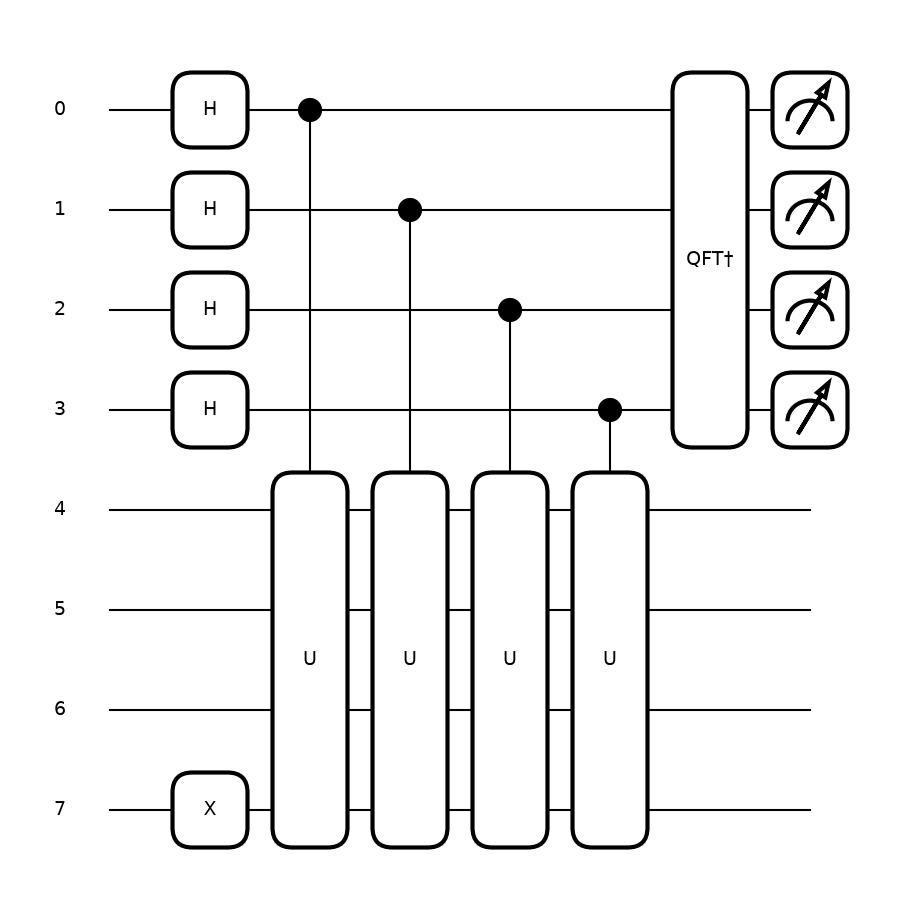

In [15]:
import matplotlib.pyplot as plt

fig, ax = qml.draw_mpl(circuit)()
plt.show()

In [18]:
probabilities = circuit()

print(f"{'Bits':<10} {'Phase':>10} {'Probability':>14}")
print("-" * 36)

for y, probability in enumerate(probabilities):
    if probability > 1e-6:
        bits = format(y, f"0{n_estimation}b")
        phase = y / (2 ** n_estimation)
        print(f"{bits:<10} {phase:>10.4f} {probability:>13.2%}")

Bits            Phase    Probability
------------------------------------
0000           0.0000        25.00%
0100           0.2500        25.00%
1000           0.5000        25.00%
1100           0.7500        25.00%


In [19]:
from fractions import Fraction

probabilities = circuit()

for y, probability in enumerate(probabilities):
    if probability < 1e-6 or y == 0:
        continue  # Ignore negligible outcomes and uninformative zero phase.

    phase = y / (2 ** n_estimation)
    fraction = Fraction(y, 2 ** n_estimation).limit_denominator(N - 1)
    r = fraction.denominator

    print(f"Phase: {phase}, fraction: {fraction}, candidate order: {r}")

    if pow(a, r, N) != 1:
        print("  Invalid order; try another outcome.")
        continue

    print(f"  Validated: {a}^{r} mod {N} = 1")

Phase: 0.25, fraction: 1/4, candidate order: 4
  Validated: 2^4 mod 15 = 1
Phase: 0.5, fraction: 1/2, candidate order: 2
  Invalid order; try another outcome.
Phase: 0.75, fraction: 3/4, candidate order: 4
  Validated: 2^4 mod 15 = 1
